### **1.Setup**

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
from IPython.display import display
import math
from scipy import stats
from scipy.stats import chi2_contingency


train_path=os.path.join("..","data","raw","train.csv")

### **2.Loading Data and First Look**

#### **2.1. Overall First Look**

In [2]:
df_raw= pd.read_csv(train_path,index_col="ID",sep=",")
print(f"Rows:{df_raw.shape[0]:,} | Columns:{df_raw.shape[1]}")
df_raw.head().T

Rows:6,534 | Columns:38


ID,10000000,10000001,10000002,10000003,10000004
Total a Pagar,558.11,978.8,10.33,856.83,1616.1
Total Bruto,510.9,830.02,12.0,696.61,1488.85
Total Liquido,453.75,795.77,8.4,696.61,1313.9
Total Imp_,104.36,183.03,1.93,160.22,302.2
Total Portes,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,57.15,34.25,3.6,0.0,174.95
Custo,153.099911,472.943134,6.097485,408.167275,485.401864
N_ Detalhes,4.0,32.0,1.0,9.0,33.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,1.0


In [3]:
#df_raw.info() shows the type of each column
df_raw.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

Purchase Date as String is a problem

#### **2.2 Grouping the Variables**

To better organize our data we chose to group the variables by themes:

In [4]:
#Variables with special structural roles
target_col = "repeat_purchase_90d"
group_col = "customer_id"
index_col = "ID"

# Grouping by themes
var_groups = {
    "Identifier": [
        "ID",
        "customer_id"
    ],
    "Target": [
        "repeat_purchase_90d"
    ],
    "Current transaction (financial)": [
        "Total a Pagar",
        "Total Bruto",
        "Total Liquido",
        "Total Imp_",
        "Total Portes",
        "Total Desc_ Global",
        "Total Desc_ Linha",
        "Custo"
    ],
    "Current transaction (operational)": [
        "N_ Detalhes",
        "invoice_count_current_purchase"
    ],
    "Transaction context & date": [
        "purchase_date",
        "payment_type",
        "salesperson",
        "commercial_zone",
        "warehouse",
        "document_series",
        "transport_method"
    ],
    "Customer historical summary": [
        "customer_tenure_days",
        "prior_purchase_count",
        "prior_total_spend",
        "prior_mean_purchase_value",
        "prior_std_purchase_value",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ],
    "Customer cadence & gaps": [
        "days_since_previous_purchase",
        "prior_mean_gap_days",
        "prior_std_gap_days"
    ],
    "Rolling windows (RFM)": [
        "purchase_count_30d",
        "spend_30d",
        "purchase_count_90d",
        "spend_90d",
        "purchase_count_180d",
        "spend_180d",
        "purchase_count_365d",
        "spend_365d"
    ],
    "Synthetic / Control": [
        "random_noise"
    ]
}
pd.DataFrame(
    [(group, len(cols), ", ".join(cols)) for group, cols in var_groups.items()], columns=["Group", "# vars", "Variables"])

,Group,# vars,Variables
0,Identifier,2,"ID, customer_id"
1,Target,1,repeat_purchase_90d
2,Current transaction (financial),8,"Total a Pagar, Total Bruto, Total Liquido, Tot..."
3,Current transaction (operational),2,"N_ Detalhes, invoice_count_current_purchase"
4,Transaction context & date,7,"purchase_date, payment_type, salesperson, comm..."
5,Customer historical summary,7,"customer_tenure_days, prior_purchase_count, pr..."
6,Customer cadence & gaps,3,"days_since_previous_purchase, prior_mean_gap_d..."
7,Rolling windows (RFM),8,"purchase_count_30d, spend_30d, purchase_count_..."
8,Synthetic / Control,1,random_noise


#### **2.3.The Target and the Floor**

In [5]:
balance = df_raw[target_col].value_counts().sort_index()
print(balance.to_frame("rows").assign(share=lambda f: (f["rows"] / f["rows"].sum()).round(3)).to_string())

# The two floors: always predict the majority class (accuracy), and always predict 1 (F1 of class 1).
p = df_raw[target_col].mean()
print(f"\nalways predict 1 -> accuracy {p:.3f} | F1(class 1) {2 * p / (1 + p):.3f}")
print(f"always predict 0 -> accuracy {1 - p:.3f} | F1(class 1) 0.000")

                     rows  share
repeat_purchase_90d             
0                    2880  0.441
1                    3654  0.559

always predict 1 -> accuracy 0.559 | F1(class 1) 0.717
always predict 0 -> accuracy 0.441 | F1(class 1) 0.000


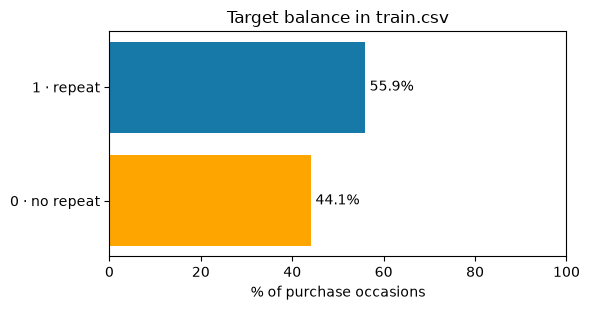

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.2))
shares = df_raw[target_col].value_counts(normalize=True).sort_index() * 100
ax.barh(["0 · no repeat", "1 · repeat"], shares.values, color=["#C96A00", "#1779A8"])
for i, v in enumerate(shares.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set(xlim=(0, 100), xlabel="% of purchase occasions", title="Target balance in train.csv")
plt.tight_layout()
plt.show()

**What this tells us**

* The classes are **mildly imbalanced, and class 1 is the majority** (≈56%). That is unusual: in most screening
  problems the positive class is rare.
* Because the competition scores the **F1 of class 1**, the trivial model "everybody comes back" already scores
  **F1 ≈ 0.72**. F1 ignores true negatives, so predicting 1 is cheap and missing a 1 is expensive.
* Two consequences for later: (1) every F1 we report will be compared with the all-ones floor, and
  (2) the decision **threshold** is part of the model. The default 0.5 is not necessarily the one that maximises F1.
* Resampling (SMOTE, undersampling) is not needed: the minority class still has ≈2,900 rows.

###  **3. Data Quality Assessment**

  Before changing anything, we first diagnose the problems.

#### **3.1. Rows with no information**

Before looking at each column, we look at each row, to see how much information each row gives us.

In [7]:
row_missing_percentage = pd.DataFrame({
    'customer_id': df_raw['customer_id'],
    'n_missing': df_raw.isna().sum(axis=1),
    'pct_missing': (df_raw.isna().sum(axis=1) * 100) / df_raw.shape[1]})

row_missing_percentage = (
    row_missing_percentage
    .set_index("customer_id")
    .query("n_missing > 19")
    .sort_values("n_missing", ascending=False))

print(f"There are {row_missing_percentage.shape[0]} rows with at least 50% of missing values")
row_missing_percentage

There are 65 rows with at least 50% of missing values


,n_missing,pct_missing
customer_id,,
755628,36,94.736842
755628,36,94.736842
427118,36,94.736842
508217,36,94.736842
427118,36,94.736842
...,...,...
151492,36,94.736842
230585,36,94.736842
902830,36,94.736842


In [8]:
# rows where everything is missing except customer_id and the target
empty_rows = df_raw.drop(columns=["customer_id", "repeat_purchase_90d"]).isna().all(axis=1)
print(f"Empty rows: {empty_rows.sum()}")

# df is our working copy without the empty rows (df_raw stays untouched)
df = df_raw.loc[~empty_rows]
print(f"Rows in df: {df.shape[0]:,}")

Empty rows: 65
Rows in df: 6,469


There are 65 rows with more than 50% of missing values, and in fact they only have `customer_id` and the target. We **consider them disposable because they do not give us enough information**, so from now on we analyse `df`, which is `df_raw` without these 65 rows.

#### **3.2. Duplicates**

In [9]:
n_dup_rows=df_raw.duplicated().sum()  #rows that are 100% identical in the raw file
print(f"Fully duplicated rows (raw file): {n_dup_rows}")
print(f"Fully duplicated rows (without the empty rows): {df.duplicated().sum()}")

n_dup_ids=df["customer_id"].duplicated().sum() #repeated client IDs
n_client_ids= df["customer_id"].nunique()
print(f"Duplicated client_id  : {n_dup_ids}")
print(f"Number of clients : {n_client_ids}")
print(f"Number of receipts/clients: {(len(df)/n_client_ids):.2f}")

Fully duplicated rows (raw file): 10
Fully duplicated rows (without the empty rows): 0
Duplicated client_id  : 5862
Number of clients : 607
Number of receipts/clients: 10.66


In the raw file there are 10 fully duplicated rows, but they are all empty rows: two empty rows of the same client look the same. Without the empty rows there are **no duplicated purchases**.

The repeated `customer_id` is not a problem: there are 6,469 purchases from 607 clients, about 10.7 purchases per client. This means the rows of the same client are not independent, which we have to keep in mind when we split the data for validation.

#### **3.3. Missing Values**

In [10]:
missing_values=(df.isna().sum().to_frame("n_missing").assign(percentage=lambda x: (x["n_missing"]*100/len(df))).query("n_missing>0").sort_values("percentage", ascending=False))
missing_values

,n_missing,percentage
prior_std_gap_days,1413,21.842634
prior_mean_gap_days,1243,19.214716
prior_std_purchase_value,1048,16.200340
prior_mean_purchase_value,797,12.320297
days_since_previous_purchase,796,12.304838
prior_min_purchase_value,603,9.321379
prior_max_purchase_value,603,9.321379
transport_method,196,3.029835
spend_365d,195,3.014376
payment_type,195,3.014376


In [11]:
# Hypothesis 1: history columns are missing because the customer has (almost) no history.
history_missing = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
                   "prior_min_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]
prior_n = df["prior_purchase_count"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
table = (df[history_missing].isna()
         .groupby(prior_n).mean().mul(100).round(1)
         .assign(rows=prior_n.value_counts()))
table.index.name = "prior purchases"
table

,days_since_previous_purchase,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_mean_gap_days,prior_std_gap_days,rows
prior purchases,,,,,,,
0,100.0,100.0,100.0,100.0,100.0,100.0,603
1,4.3,4.5,100.0,0.0,100.0,100.0,445
2,5.5,3.0,0.0,0.0,5.8,100.0,365
3+,3.0,3.2,0.0,0.0,3.4,0.0,5056


The hypothesis holds **only in part**:

* With **0 prior purchases**, every history column is missing in 100% of rows, as expected: there is no history.
* With **1 prior purchase**, the gap and the standard deviations are always missing (one purchase has no gap and no
  spread), but `days_since_previous_purchase` should exist, and it is still missing for a fraction of rows.
* With **2 or more** prior purchases, all these columns *should* exist, yet a few percent are missing anyway. That
  part is ordinary missingness, not structural.

So "missing = no history" (the business-logic reading, MNAR) explains most but not all of it. This decides the fix: we
add an explicit flag such as `is_first_purchase` (`prior_purchase_count == 0`) and *missing indicators*, then impute
the remaining gaps with the **training median**. We do **not** fill gaps with 0: a gap of 0 days would mean "buys every
day", which is the opposite of "no history".

Without the empty rows, the invoice columns, `commercial_zone`, `document_series`, `purchase_date` and the rolling windows have **no missing values**. The real missing values are only in the history columns and in some context columns (about 3% each).

Some history columns have around 20% of missing values, but we do **not** drop them: the missing values are mostly structural (clients without previous purchases), and these columns are among the most important ones for the target (for example `prior_mean_gap_days`). Dropping them would lose a lot of information.

#### **3.4. Inconsistent Categories**

In [12]:
cat_cols = df.select_dtypes(include=['object', 'category', 'str']).columns.tolist()
cat_cols.remove("purchase_date")  # it is a date, not a category
for col in cat_cols:
    print(f"{col:<10} -> {df[col].nunique()} distinct values")

payment_type -> 9 distinct values
salesperson -> 9 distinct values
commercial_zone -> 5 distinct values
transport_method -> 80 distinct values
warehouse  -> 2 distinct values
document_series -> 3 distinct values


Each category is always written in the same way, so there are no spelling variants to fix. The real problem is the **rare levels**: some levels appear only a few times (for example `commercial_zone` 6 and 7 with 1 row each, and many `transport_method` levels with only 1 row). Lets look at each column.

In [13]:
df["payment_type"].value_counts(dropna=False)

payment_type
Maybe Tomorrow Payment 7     4565
Maybe Tomorrow Payment 12     991
Maybe Tomorrow Payment 9      502
NaN                           195
Maybe Tomorrow Payment 10     134
Maybe Tomorrow Payment 8       40
Maybe Tomorrow Payment 2       21
Maybe Tomorrow Payment 4        9
Maybe Tomorrow Payment 11       8
Maybe Tomorrow Payment 3        4
Name: count, dtype: int64

In [14]:
df[("salesperson")].value_counts(dropna=False)

salesperson
VLOOKUP Master 1    4054
VLOOKUP Master 4    1461
VLOOKUP Master 9     384
VLOOKUP Master 7     201
NaN                  194
VLOOKUP Master 2     123
VLOOKUP Master 3      30
VLOOKUP Master 6      12
VLOOKUP Master 5       7
VLOOKUP Master 8       3
Name: count, dtype: int64

In [15]:
df[("commercial_zone")].value_counts(dropna=False)

commercial_zone
Decorative Dashboard Zone 4    6260
Decorative Dashboard Zone 2     151
Decorative Dashboard Zone 3      56
Decorative Dashboard Zone 6       1
Decorative Dashboard Zone 7       1
Name: count, dtype: int64

This category is fine and has no missing values once the empty rows are removed. Zones 6 and 7 only have 1 row each, so they are rare levels.

In [16]:
df["transport_method"].isna().sum()
print(f"There are {df["transport_method"].isna().sum()} NaNs in this category")
df["transport_method"].value_counts(dropna=False)

There are 196 NaNs in this category


transport_method
Maybe Tomorrow Delivery 72    1119
Maybe Tomorrow Delivery 61     627
Maybe Tomorrow Delivery 73     445
Maybe Tomorrow Delivery 59     373
Maybe Tomorrow Delivery 80     319
                              ... 
Maybe Tomorrow Delivery 55       1
Maybe Tomorrow Delivery 58       1
Maybe Tomorrow Delivery 28       1
Maybe Tomorrow Delivery 21       1
Maybe Tomorrow Delivery 23       1
Name: count, Length: 81, dtype: int64

In [17]:
df[("warehouse")].value_counts(dropna=False)

warehouse
Final Excel Warehouse 1    6253
NaN                         195
Final Excel Warehouse 3      21
Name: count, dtype: int64

In [18]:
df[("document_series")].value_counts(dropna=False)

document_series
Ctrl Z Series 2    2738
Ctrl Z Series 3    1903
Ctrl Z Series 1    1828
Name: count, dtype: int64

#### **3.5. Wrong Data Types**

#### **3.5.1. Dates**

In [20]:
# Date columns: check which formats are used by replacing every digit with "9"
patterns = df["purchase_date"].astype(str).str.replace(r"\d", "9", regex=True).value_counts()
print(f"{"date format":<18}", patterns.to_dict())
print(f"{"missing values":<18}", df[("purchase_date")].isna().sum())

date format        {'9999-99-99': 6469}
missing values     0


The dates are all in the format 9999-99-99, and there are no missing dates once the empty rows are removed.

#### **3.6. Impossible Values**

In [21]:
cols_num = df.select_dtypes(include=["number"]).columns.tolist()
df[cols_num].describe().T[["min","25%","50%","75%","max"]].round(2)

,min,25%,50%,75%,max
Total a Pagar,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,0.00,0.00,13.13,92.28,4.103440e+03
Custo,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,1.00,1.00,1.00,1.00,5.000000e+00


Three things cannot be true:

* `prior_mean_purchase_value` and `spend_365d` reach **1,000,000,000** (one billion euros), while their medians are
  ≈725 € and ≈2,400 €.
* `days_since_previous_purchase` and `prior_mean_gap_days` have **negative** values (a gap cannot be negative), and
  `prior_mean_purchase_value` and `spend_365d` too (spending cannot be negative).

Random damage would scatter over many values. Placeholders sit on a few exact values, so we look at the values themselves.

In [22]:
checks = {
    "prior_mean_purchase_value": df["prior_mean_purchase_value"],
    "spend_365d": df["spend_365d"],
    "days_since_previous_purchase": df["days_since_previous_purchase"],
    "prior_mean_gap_days": df["prior_mean_gap_days"],
}
for name, s in checks.items():
    bad = s[(s < 0) | (s >= 1e8)]
    print(f"{name:30s} {len(bad):3d} impossible values -> {bad.value_counts().head(4).to_dict()}")

prior_mean_purchase_value       32 impossible values -> {1000000000.0: 16, -110.14709677419351: 1, -409.7916666666667: 1, -218.2663917525773: 1}
spend_365d                      30 impossible values -> {1000000000.0: 15, -3456.32: 1, -1230.72: 1, -167.18: 1}
days_since_previous_purchase    16 impossible values -> {-4.0: 16}
prior_mean_gap_days             16 impossible values -> {-4.0: 16}


We have observed that the values 1e9 and -4 are exact repeated values, so they look like codes and not real values. They are impossible values considering the financial context. Before deciding what to do, we check if the real value can be recovered from other columns.

##### **3.6.1. Impossible Values of "Prior_mean_purchase_value"**

Lets examinate the negative values of "prior_mean_purchase_value":

In [23]:
df[df["prior_mean_purchase_value"]<0].T

ID,10000018,10000519,10000536,10001157,10001375,10001461,10002281,10002605,10002989,10003383,10003794,10003949,10005413,10006099,10006217,10006219
Total a Pagar,2460.0,221.74,4.65,473.82,423.46,105.29,43.01,2923.88,377.3,93.81,491.61,56.79,502.17,27.8,144.13,592.97
Total Bruto,2000.0,180.28,5.4,447.0,646.53,122.28,49.95,2587.5,409.0,88.5,399.68,54.52,472.96,22.6,117.18,791.45
Total Liquido,2000.0,180.28,3.78,447.0,344.28,85.6,34.97,2587.5,306.75,88.5,399.68,46.17,408.27,22.6,117.18,482.09
Total Imp_,460.0,41.46,0.87,26.82,79.18,19.69,8.04,336.38,70.55,5.31,91.93,10.62,93.9,5.2,26.95,110.88
Total Portes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.1,3.1,5.6,0.0,0.0,4.2
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,0.0,0.0,1.62,0.0,302.25,36.68,14.98,0.0,102.25,0.0,0.0,8.35,64.69,0.0,0.0,309.36
Custo,0.0,140.628,2.97,289.5,149.968648,61.08,16.29,0.0,123.74,57.9,227.21,3.56634,150.857,17.78,57.811668,189.475636
N_ Detalhes,1.0,6.0,1.0,58.0,30.0,3.0,1.0,1.0,3.0,8.0,14.0,3.0,10.0,2.0,7.0,44.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [24]:
recomputed_mean = df["prior_total_spend"] / df["prior_purchase_count"].replace(0, np.nan)
stored_mean = df["prior_mean_purchase_value"]

is_billion = stored_mean >= 1e8
is_negative = stored_mean < 0
is_normal = stored_mean.notna() & ~is_billion & ~is_negative
pd.DataFrame({
    "prior_total_spend": df.loc[is_negative, "prior_total_spend"],
    "prior_purchase_count": df.loc[is_negative, "prior_purchase_count"],
    "total / count": recomputed_mean[is_negative],
    "stored prior_mean_purchase_value": stored_mean[is_negative],
}).head(5).round(2)

,prior_total_spend,prior_purchase_count,total / count,stored prior_mean_purchase_value
ID,,,,
10000018,3414.56,31.0,110.15,-110.15
10000519,2458.75,6.0,409.79,-409.79
10000536,42343.68,194.0,218.27,-218.27
10001157,2925.42,7.0,417.92,-417.92
10001375,3895.15,5.0,779.03,-779.03


**The 16 negative values are a sign error**: in every one of them, the stored value is exactly
  `−(prior_total_spend / prior_purchase_count)`. There is no business logic behind a negative mean.

In [25]:
pd.DataFrame({
    "rows": [is_normal.sum(), is_negative.sum(), is_billion.sum()],
    "stored = total / count": [np.isclose(stored_mean[m], recomputed_mean[m]).mean()
                               for m in (is_normal, is_negative, is_billion)],
    "|stored| = total / count": [np.isclose(stored_mean[m].abs(), recomputed_mean[m]).mean()
                                 for m in (is_normal, is_negative, is_billion)],
    "total / count can be computed": [recomputed_mean[m].notna().mean()
                                      for m in (is_normal, is_negative, is_billion)],
}, index=["normal values", "negative values", "1e9 values"]).round(3)

,rows,stored = total / count,|stored| = total / count,total / count can be computed
normal values,5640,0.992,0.992,1.0
negative values,16,0.000,1.000,1.0
1e9 values,16,0.000,0.000,1.0


**The formula holds**: for 99.2% of the normal rows, the stored mean is exactly total / count.

**The 16 values of 1e9 can be recovered as well**: all these customers have previous purchases, so total / count can
  be computed for every one of them.

#### 3.6.2 And the negative values of `spend_365d`?

`spend_365d` cannot be recomputed from other columns, but it must respect two bounds: it includes the last 180 days, so
it is at least `spend_180d`, and it is part of the whole history, so it is at most `prior_total_spend`. We check
whether the negative values fit these bounds once the sign is removed.

In [26]:
spend = df["spend_365d"]
spend_negative = spend < 0
spend_billion = spend >= 1e8
spend_normal = spend.notna() & ~spend_negative & ~spend_billion


def inside_bounds(values, rows):
    """True where a 365-day spend lies between the 180-day spend and the full prior spend (1 cent tolerance)."""
    return ((values >= df.loc[rows, "spend_180d"] - 0.01)
            & (values <= df.loc[rows, "prior_total_spend"] + 0.01))


pd.DataFrame({
    "rows": [spend_normal.sum(), spend_negative.sum()],
    "value inside the bounds": [inside_bounds(spend[spend_normal], spend_normal).mean(),
                                inside_bounds(spend[spend_negative], spend_negative).mean()],
    "|value| inside the bounds": [inside_bounds(spend[spend_normal].abs(), spend_normal).mean(),
                                  inside_bounds(spend[spend_negative].abs(), spend_negative).mean()],
}, index=["normal spend_365d", "negative spend_365d"]).round(3)

,rows,value inside the bounds,|value| inside the bounds
normal spend_365d,6244,0.994,0.994
negative spend_365d,15,0.000,0.933


In [27]:
# The negative value that does not fit the bounds even without its sign
outside = spend_negative & ~inside_bounds(spend.abs(), df.index)
df.loc[outside, ["spend_180d", "spend_365d", "prior_total_spend"]]

,spend_180d,spend_365d,prior_total_spend
ID,,,
10004848,5631.64,-159115.175535,49328.65


* **14 of the 15 negative values fit the bounds once the sign is removed**, so a sign error is possible (99.4% of the normal values respect the same bounds).
* **One value cannot be explained**: −159,115 € in absolute value is three times the customer's whole prior spend
  (49,329 €). No correction is defensible, so it is treated as unknown.
* The 15 values of **1e9** in `spend_365d` cannot be reconstructed from other columns either.

But is fitting the bounds enough to trust the sign correction? We check how often a random `spend_365d` value would also fit the bounds of these rows.

In [28]:
# for each of the 14 rows, how many normal spend_365d values (taken at random) would also fit its bounds?
pool = spend[spend_normal]
fits = spend_negative & inside_bounds(spend.abs(), df.index)
chance = []
for row in df.index[fits]:
    low, high = df.loc[row, "spend_180d"], df.loc[row, "prior_total_spend"]
    chance.append(((pool >= low - 0.01) & (pool <= high + 0.01)).mean())
print(f"On average {np.mean(chance):.0%} of random values would also fit the bounds")

On average 45% of random values would also fit the bounds


About 45% of random values would also fit, because the bounds are wide. So the bounds do not prove that only the sign is wrong: the whole value could be a recording error. This is different from `prior_mean_purchase_value`, where the value is exactly equal to total / count, which a random value would almost never be.

So we do **not** just remove the minus sign: the 15 negative values of `spend_365d` will be treated as missing (NaN) and imputed with the median in Part 2. The median has to be computed only on the training rows, inside the pipeline, to avoid leakage, and we use the median and not the mean because the column is very skewed. This only affects 15 rows.

##### **3.6.3. Values that look normal but are not**

The bounds above can also be checked on the "normal" values. A mean purchase value cannot be bigger than the biggest purchase of the client, and the spend of the last 365 days cannot be bigger than the whole prior spend.

In [29]:
# mean bigger than the max purchase of the client
mean_too_high = is_normal & (stored_mean > df["prior_max_purchase_value"] + 0.01)
print(f"prior_mean_purchase_value bigger than prior_max_purchase_value: {mean_too_high.sum()}")
print(f"normal values that do not match total / count: {(is_normal & ~np.isclose(stored_mean, recomputed_mean)).sum()}")

# spend of the last 365 days bigger than the whole prior spend
spend_too_high = spend_normal & (spend > df["prior_total_spend"] + 0.01)
print(f"spend_365d bigger than prior_total_spend: {spend_too_high.sum()}")

# missing means that can be computed with total / count
print(f"prior_mean_purchase_value missing but computable: {(stored_mean.isna() & recomputed_mean.notna()).sum()}")

prior_mean_purchase_value bigger than prior_max_purchase_value: 45
normal values that do not match total / count: 46
spend_365d bigger than prior_total_spend: 39
prior_mean_purchase_value missing but computable: 194


* 46 "normal" means do not match total / count, and in 45 of them the mean is bigger than the biggest purchase of the client, which is impossible. These values look fine alone, so `describe()` could not show them. Since total / count always works, we can recompute `prior_mean_purchase_value` for every row.
* 39 values of `spend_365d` are bigger than the whole prior spend of the client, also impossible. There is no formula to recover them, so they will be treated as missing.
* 194 missing values of `prior_mean_purchase_value` can be computed with total / count, so they are not really missing.

##### **3.6.3.1. What if both negatives are all on the same row?**

We test the hypothesis that `prior_mean_purchase_value` and `spend_365d` are negative in the same rows. If this is true, the minus sign is probably a typing error that affects the whole row, and removing it would be easier to defend. If not, we keep the decision we took before.

In [63]:
# 1. Identificar a coluna de gastos relevante (ajuste o nome se necessário)
col_spend = "spend_365d" if "spend_365d" in df_raw.columns else [c for c in df_raw.columns if "spend" in c.lower()][0]

# 2. Filtrar apenas as linhas onde pelo menos uma das duas colunas tem valores negativos
mask_negatives = (df_raw["prior_mean_purchase_value"] < 0) | (df_raw[col_spend] < 0)

# 3. Criar a tabela comparativa lado a lado com colunas-chave para inspeção manual
cols_to_see = [
    "customer_id", 
    "prior_mean_purchase_value", 
    col_spend, 
    "prior_total_spend", 
    "prior_purchase_count"
]

df_comparing = df_raw.loc[mask_negatives, cols_to_see].head(25)

print(f"Rows with negative values: {mask_negatives.sum()}")
display(df_comparing)

Rows with negative values: 31


,customer_id,prior_mean_purchase_value,spend_365d,prior_total_spend,prior_purchase_count
ID,,,,,
10000018,239651,-110.147097,1019.820000,3414.56,31.0
10000300,928271,691.264000,-3456.320000,3456.32,5.0
10000519,933227,-409.791667,NaN,2458.75,6.0
10000536,103940,-218.266392,13067.220000,42343.68,194.0
10001157,568558,-417.917143,567.230000,2925.42,7.0
10001375,215423,-779.030000,3261.060000,3895.15,5.0
10001461,103940,-212.360622,14030.610000,44383.37,209.0
10002022,449027,732.742857,-1230.720000,5129.20,7.0
10002033,981754,172.458667,-167.180000,2586.88,15.0


The two columns are never negative in the same row. So the negative values are not an error of the whole row, and we keep the decision we took before: `prior_mean_purchase_value` is recomputed as total / count, and the negative values of `spend_365d` are treated as missing.

#### **3.7. Summary of the data quality problems**

| Problem | Rows | What we will do (Part 2) |
|---|---|---|
| Empty rows (only `customer_id` and target) | 65 | drop |
| Duplicated rows | 10 in the raw file, all empty rows; 0 after removing them | nothing |
| Missing values in the history columns (no previous purchase) | 600 to 1,400 per column | flag for first purchase + impute with the train median |
| Missing values in the context columns | about 195 per column | new category "Missing" |
| Rare categories | many in `transport_method` | group into "Other" |
| `purchase_date` as text | all | convert to datetime |
| `prior_mean_purchase_value` negative, 1e9, inflated or missing but computable | 16 + 16 + 46 + 194 | recompute as total / count |
| `spend_365d` negative (sign error not provable), 1e9 or bigger than the prior spend | 15 + 15 + 39 | missing, then impute with the train median |
| Gaps of -4 days | 16 + 16 | missing, then impute |

### **4.Outliers Values**

During the Data Quality Assessment, records exhibiting extreme values or specialized distributions were carefully evaluated rather than automatically discarded. In a financial and behavioral dataset, high-value outliers and long-tail distributions (right-skewness) typically represent legitimate, high-value customer segments (e.g., VIPs or corporate accounts) rather than system corruption.

Consequently, wholesale removal or dropping of these records would result in a critical loss of valuable business information and introduce selection bias. Instead of deletion, structural technical errors (such as legacy placeholders or sign-inversion artifacts) are isolated and corrected programmatically (e.g., via absolute value adjustment or targeted data cleaning). For valid extreme values, analytical transformations (such as, logarithmic scaling (log1p)) will be applied during the feature engineering phase. This approach preserves the economic significance of top-tier accounts while stabilizing variance for subsequent machine learning models.

### **5. Time Structure**

Every purchase has a date, and the model will always be used to predict purchases that happen after the ones it learned from. Lets see how the data changes over time.

In [30]:
# convert the date (it was read as string, see 3.5.1)
purchase_dates = pd.to_datetime(df["purchase_date"])
print(f"First purchase: {purchase_dates.min().date()} | Last purchase: {purchase_dates.max().date()}")

# number of purchases and repeat rate per year
by_year = df.groupby(purchase_dates.dt.year)[target_col].agg(["count", "mean"])
by_year.columns = ["rows", "repeat rate"]
by_year.index.name = "year"
by_year.round(3)

First purchase: 2015-07-11 | Last purchase: 2025-02-15


,rows,repeat rate
year,,
2015,335,0.534
2016,420,0.514
2017,670,0.633
2018,716,0.538
2019,646,0.522
2020,670,0.594
2021,782,0.549
2022,628,0.481
2023,767,0.581


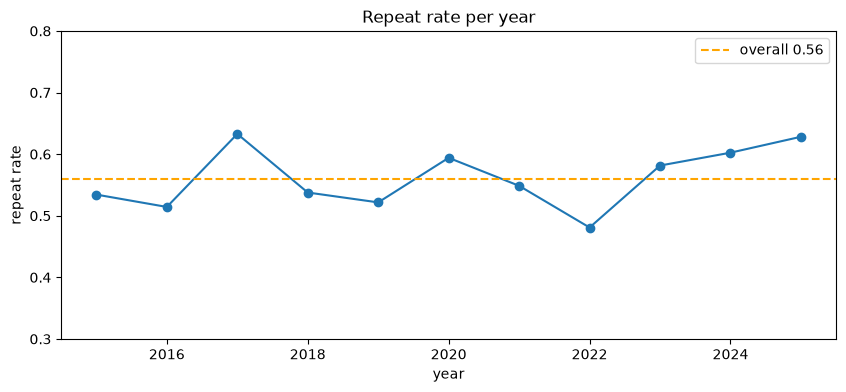

In [31]:
plt.figure(figsize=(10, 4))
plt.plot(by_year.index, by_year["repeat rate"], marker="o")
plt.axhline(df[target_col].mean(), color="orange", linestyle="--", label=f"overall {df[target_col].mean():.2f}")
plt.ylim(0.3, 0.8)
plt.xlabel("year")
plt.ylabel("repeat rate")
plt.title("Repeat rate per year")
plt.legend()
plt.show()

The repeat rate is not the same every year: it goes from 0.48 (2022) to 0.63 (2017 and 2025), and the last years are above the overall average. This means the population changes over time (population drift), so the clients the model will see in the future are not exactly the same as the ones it learned from. 2025 only has 78 rows because the data ends in February 2025.

In [32]:
# how many of the recent purchases come from clients we already knew?
recent = purchase_dates >= "2023-01-01"
old_clients = set(df.loc[~recent, "customer_id"])
recent_clients = set(df.loc[recent, "customer_id"])

print(f"Purchases from 2023 onwards: {recent.sum():,}")
print(f"Made by clients who already bought before 2023: {df.loc[recent, 'customer_id'].isin(old_clients).mean():.1%}")
print(f"Clients active since 2023: {len(recent_clients)} | new clients: {len(recent_clients - old_clients)}")

Purchases from 2023 onwards: 1,602
Made by clients who already bought before 2023: 89.5%
Clients active since 2023: 261 | new clients: 57


Almost 90% of the recent purchases come from clients that already bought before. Clients keep coming back over many years, so a future purchase will usually belong to a client that already has history in the data.

In [33]:
# median of some variables in 3 periods
period = pd.cut(purchase_dates.dt.year, bins=[2014, 2018, 2022, 2025], labels=["2015-2018", "2019-2022", "2023-2025"])
cols_time = ["Total a Pagar", "N_ Detalhes", "days_since_previous_purchase", "purchase_count_90d", "spend_90d",
             "purchase_count_365d", "customer_tenure_days", "prior_purchase_count", "prior_total_spend"]
df.groupby(period, observed=True)[cols_time].median().T.round(1)

purchase_date,2015-2018,2019-2022,2023-2025
Total a Pagar,382.1,489.5,634.4
N_ Detalhes,9.0,12.0,15.0
days_since_previous_purchase,49.0,63.0,61.0
purchase_count_90d,1.0,1.0,1.0
spend_90d,147.9,162.6,352.6
purchase_count_365d,3.0,4.0,4.0
customer_tenure_days,309.0,1238.5,2082.0
prior_purchase_count,4.0,15.0,21.0
prior_total_spend,2275.8,9004.0,15013.7


* The **cumulative variables grow with time** just because the company and the clients get older: the median tenure goes from 309 to 2,082 days and the prior total spend from 2,276 € to 15,014 €. The money values also go up (the median invoice goes from 382 € to 634 €).
* The **behaviour variables stay stable**: the days since the previous purchase (around 50-60) and the number of purchases in the last 90 or 365 days almost do not change.

**What we take from this:**
* The model will always predict the future, so the validation should also be **temporal**: train on the older years and validate on the most recent ones. A random split would mix past and future.
* We will **not use the year** of the purchase as a variable, because any future purchase will be in a year the model never saw.
* The cumulative variables will always be a bit higher in the future, so the behaviour variables (recency, frequency in fixed windows) are the safer ones.

### **6.Univariate Analysis**

For this part we use a copy of `df` with the corrections we decided in 3.6, so the wrong values do not change the statistics. The missing values are **not** filled here (that is done in Part 2), so every statistic only uses the values that exist.

In [34]:
# exploration copy with the corrections of 3.6 (df stays the same)
df_eda = df.copy()

# prior_mean_purchase_value is total / count, so we recompute it for every row
df_eda["prior_mean_purchase_value"] = df_eda["prior_total_spend"] / df_eda["prior_purchase_count"].replace(0, np.nan)

# spend_365d: 1e9, negative or bigger than the whole prior spend -> missing
bad_spend = (df_eda["spend_365d"] >= 1e8) | (df_eda["spend_365d"] < 0) | (df_eda["spend_365d"] > df_eda["prior_total_spend"] + 0.01)
df_eda.loc[bad_spend, "spend_365d"] = np.nan

# gaps of -4 days -> missing
for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    df_eda.loc[df_eda[col] < 0, col] = np.nan

print(f"spend_365d values set to missing: {bad_spend.sum()}")

spend_365d values set to missing: 69


In [35]:
# How many rows would the 1.5 x IQR rule call outliers, and do those clients buy again?
for col in ["Total a Pagar", "prior_total_spend", "prior_purchase_count", "N_ Detalhes"]:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    out = s > q3 + 1.5 * (q3 - q1)
    print(f"{col:22s} {100 * out.mean():.1f}% flagged | repeat rate flagged {df.loc[out[out].index, 'repeat_purchase_90d'].mean():.2f}"
          f" vs rest {df.loc[out[~out].index, 'repeat_purchase_90d'].mean():.2f}")

Total a Pagar          9.2% flagged | repeat rate flagged 0.67 vs rest 0.55
prior_total_spend      9.9% flagged | repeat rate flagged 0.84 vs rest 0.53
prior_purchase_count   7.7% flagged | repeat rate flagged 0.97 vs rest 0.53
N_ Detalhes            6.7% flagged | repeat rate flagged 0.64 vs rest 0.55


The rule flags between 7% and 10% of the rows, and these clients buy again much more than the rest (for example 0.97 vs 0.53 for `prior_purchase_count`). They are our best clients, not errors, so we keep them.

#### **6.1. Numeric Variables**

In [36]:
# numeric columns, taken from the groups of 2.2
numeric_cols = (var_groups["Current transaction (financial)"] + var_groups["Current transaction (operational)"]
                + var_groups["Customer historical summary"] + var_groups["Customer cadence & gaps"]
                + var_groups["Rolling windows (RFM)"])

shape = df_eda[numeric_cols].describe().T[["mean", "50%", "std", "max"]]
shape["mean/median"] = shape["mean"] / shape["50%"].replace(0, np.nan)
shape["skew"] = df_eda[numeric_cols].skew()
shape["% zeros"] = 100 * (df_eda[numeric_cols] == 0).mean()
shape.sort_values("skew", ascending=False).round(2)

,mean,50%,std,max,mean/median,skew,% zeros
Total Desc_ Global,0.35,0.00,5.12,218.49,NaN,27.46,98.30
prior_max_purchase_value,2946.38,1783.24,5901.55,267526.19,1.65,21.34,0.00
Total Portes,1.15,0.00,5.84,181.06,NaN,19.55,83.72
prior_mean_gap_days,96.18,68.61,122.65,3199.00,1.40,9.31,0.00
prior_std_gap_days,74.14,50.64,101.82,2212.54,1.46,7.77,0.02
days_since_previous_purchase,101.83,57.00,165.84,3199.00,1.79,6.53,0.00
invoice_count_current_purchase,1.07,1.00,0.31,5.00,1.07,6.44,0.00
Total Desc_ Linha,112.47,13.13,289.99,4103.44,8.57,5.92,37.73
prior_min_purchase_value,185.46,64.34,408.40,6298.98,2.88,5.90,0.00
spend_30d,457.14,0.00,1191.23,22297.21,NaN,5.50,67.12


Almost all the money and count variables are **very skewed to the right** (skew > 2 and the mean much bigger than the median): many small values and a long tail of very big ones. `Total Portes` and `Total Desc_ Global` are 0 in almost every row (84% and 98%), and `invoice_count_current_purchase` is almost always 1.

To be able to see the shape of these variables, the histograms of the very skewed ones (skew > 2) are shown with `log1p`. This is only for the plot, the statistics above use the original values. We use `log1p` and not `log` because many variables have zeros and log(0) does not exist.

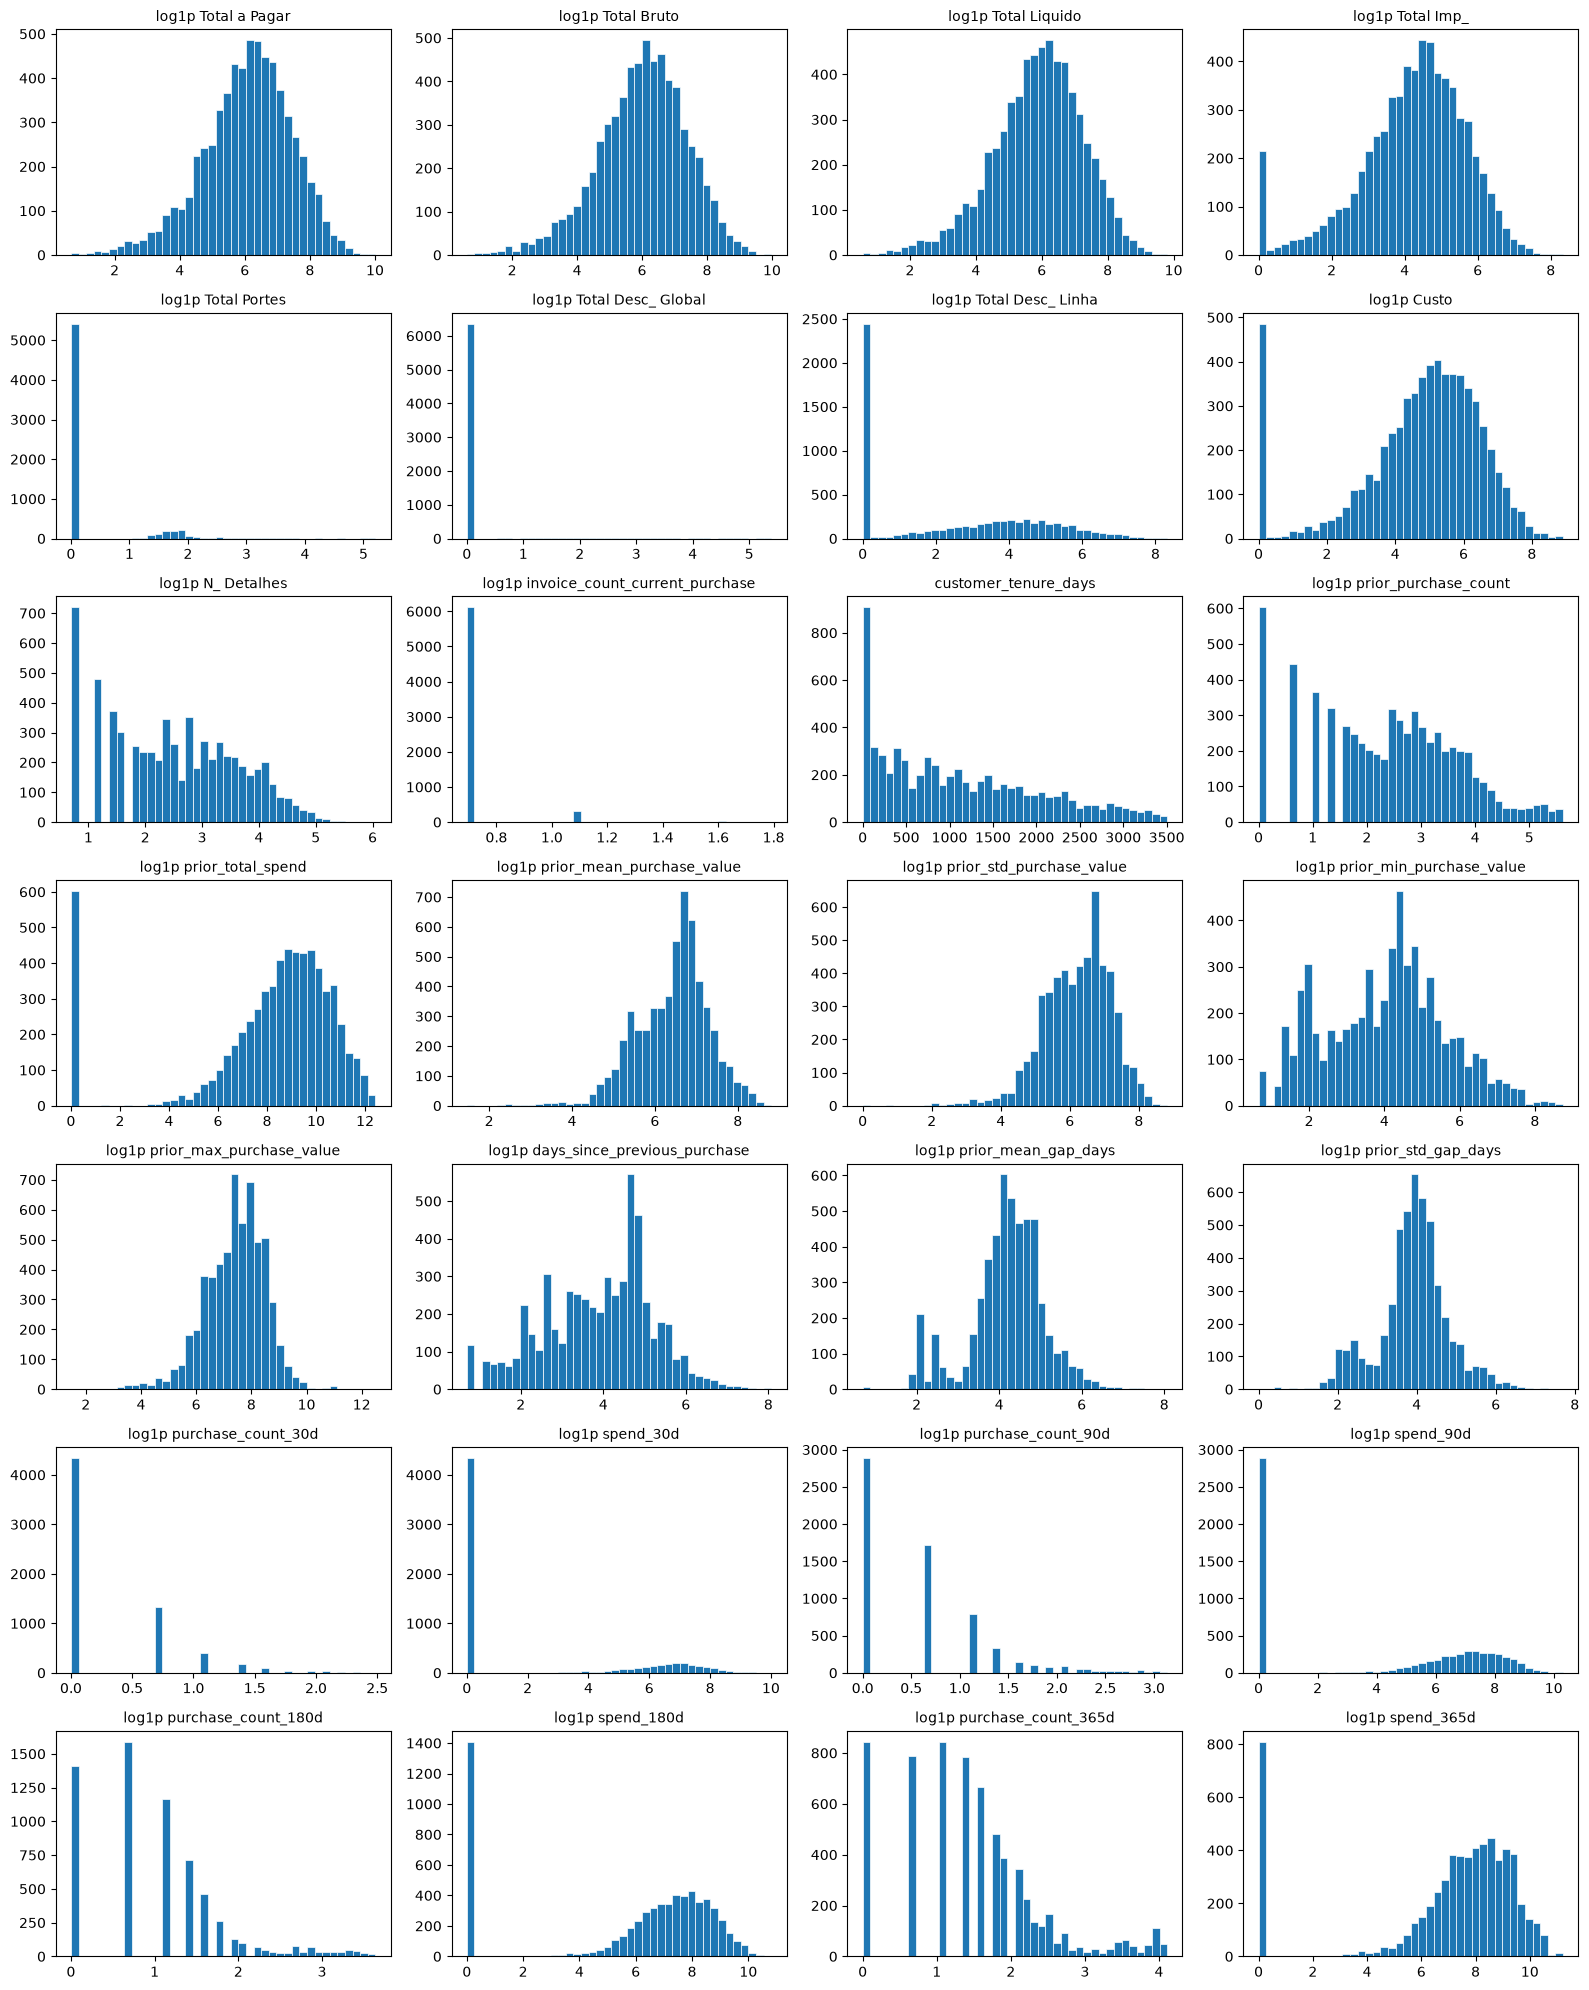

In [66]:
skewed = shape.index[shape["skew"] > 2].tolist()

fig, axes = plt.subplots(7, 4, figsize=(16, 20))
for ax, col in zip(axes.flat, numeric_cols):
    values = df_eda[col].dropna()
    if col in skewed:
        values = np.log1p(values.clip(lower=0))
        ax.set_title(f"log1p {col}", fontsize=10)
    else:
        ax.set_title(col, fontsize=10)
    ax.hist(values, bins=40, edgecolor="white", linewidth=0.5)
for ax in axes.flat[len(numeric_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

* With `log1p` most of the money variables look almost like a normal curve, so a `log1p` transformation can help the linear model in Part 2.
* The rolling windows have a lot of zeros (67% of the rows have no purchase in the last 30 days). Here a zero is information: it means no recent purchase.
* The extreme values of these variables are not errors: at the start of this section we saw that they are our best clients, so we keep them.

#### **6.2. Categorical Variables**

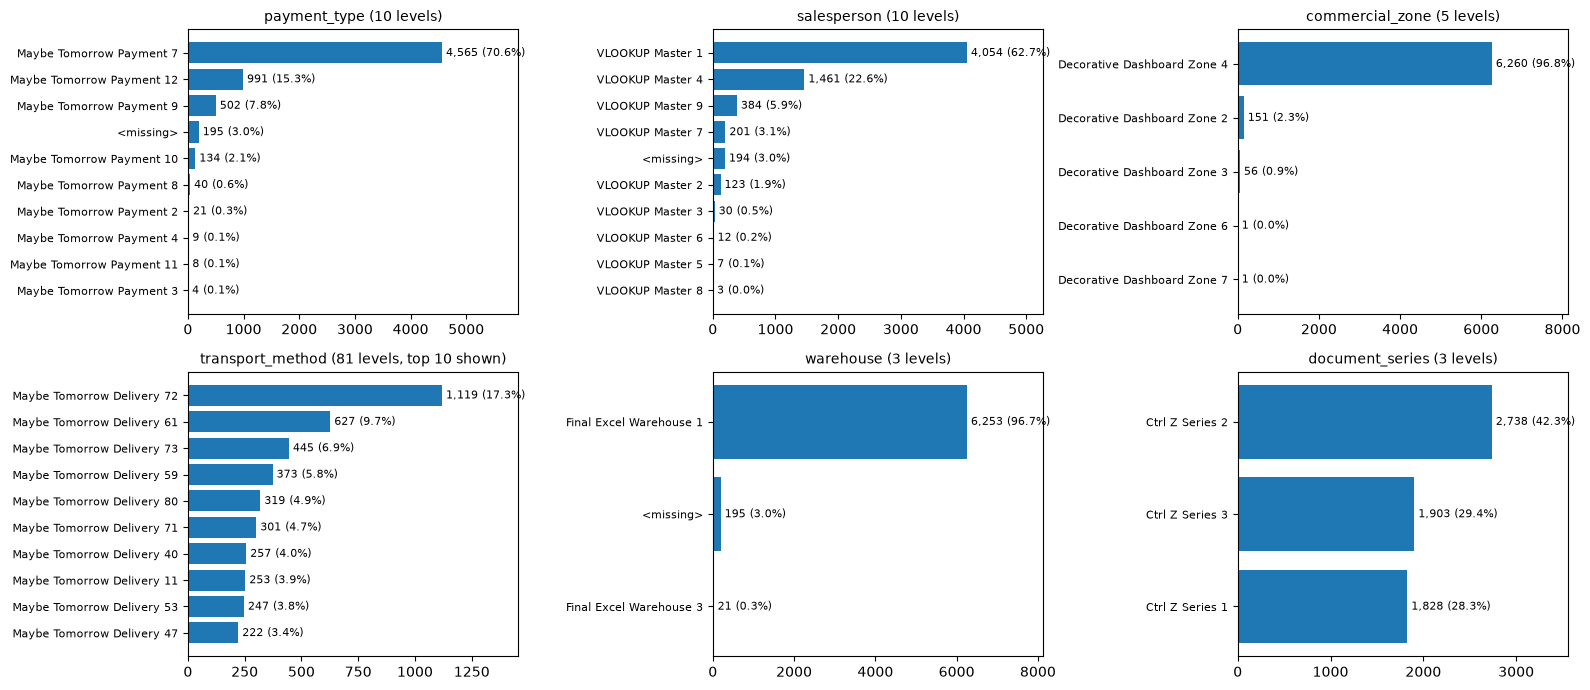

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, cat_cols):
    counts = df_eda[col].fillna("<missing>").value_counts()
    top = counts.head(10)
    ax.barh(top.index[::-1], top.values[::-1])
    # write the number and the % next to each bar (small levels are not visible otherwise)
    for i, v in enumerate(top.values[::-1]):
        ax.text(v, i, f" {v:,} ({100 * v / counts.sum():.1f}%)", va="center", fontsize=8)
    title = f"{col} ({counts.size} levels" + (", top 10 shown)" if counts.size > 10 else ")")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, counts.max() * 1.3)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

* `warehouse` (Warehouse 1 in 99.7% of the rows with a value) and `commercial_zone` (97% in Zone 4) are almost constant, so they can not say much about the target.
* `Final Excel Warehouse 3` only appears in 21 purchases of 13 clients, all between July 2015 and March 2016. After that every purchase comes from Warehouse 1, so this level marks a period and not a type of client.
* `transport_method` has a long tail: a few methods have most of the rows and many have only a few rows.
* `payment_type` and `salesperson` have one main level but are more spread.

### **7. Relationship with the Target**

#### **7.1. Numeric Variables**

To measure the relationship between each numeric variable and the target we use the **point-biserial correlation** (the correlation with a 0/1 variable), computed on the `log1p` values because the variables are very skewed. We also show the **Spearman** correlation, which uses ranks and is not affected by the extreme values, and the median of each variable in each class.

In [39]:
def signed_log1p(s):
    return np.sign(s) * np.log1p(np.abs(s))

rel_rows = []
for col in numeric_cols:
    pair = df_eda[[col, target_col]].dropna()
    r_pb, p_pb = stats.pointbiserialr(pair[target_col], signed_log1p(pair[col]))
    rho, _ = stats.spearmanr(pair[col], pair[target_col])
    rel_rows.append({"feature": col, "point-biserial r (log1p)": r_pb, "Spearman rho": rho, "p-value": p_pb,
                     "median | 0": pair.loc[pair[target_col] == 0, col].median(),
                     "median | 1": pair.loc[pair[target_col] == 1, col].median()})

relevance = pd.DataFrame(rel_rows).set_index("feature")
relevance = relevance.reindex(relevance["Spearman rho"].abs().sort_values(ascending=False).index)
relevance.round(3)

,point-biserial r (log1p),Spearman rho,p-value,median | 0,median | 1
feature,,,,,
purchase_count_365d,0.424,0.437,0.000,2.000,5.000
prior_mean_gap_days,-0.389,-0.420,0.000,101.750,55.758
purchase_count_180d,0.407,0.406,0.000,1.000,3.000
purchase_count_90d,0.396,0.393,0.000,0.000,1.000
spend_365d,0.310,0.391,0.000,1126.840,4487.740
spend_180d,0.317,0.370,0.000,457.870,2106.220
spend_90d,0.351,0.359,0.000,0.000,746.190
prior_purchase_count,0.346,0.346,0.000,6.000,17.000
prior_total_spend,0.275,0.332,0.000,3246.525,12098.990


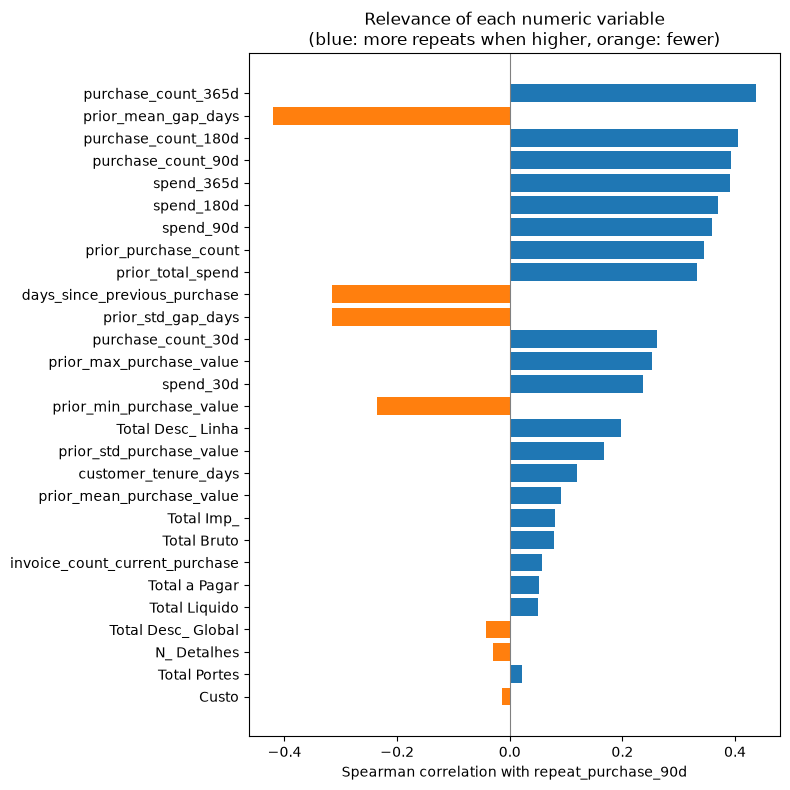

In [40]:
values = relevance["Spearman rho"]
colors = ["tab:blue" if v > 0 else "tab:orange" for v in values[::-1]]

plt.figure(figsize=(8, 8))
plt.barh(values.index[::-1], values.values[::-1], color=colors)
plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel("Spearman correlation with repeat_purchase_90d")
plt.title("Relevance of each numeric variable\n(blue: more repeats when higher, orange: fewer)")
plt.tight_layout()
plt.show()

* **Recency and frequency are the strongest signals.** The clients who bought more times in the last 90, 180 and 365 days come back more (for example `purchase_count_365d`: median of 2 purchases for class 0 and 5 for class 1), and the clients with smaller gaps between purchases also come back more (`prior_mean_gap_days`: median of 102 days for class 0 and 56 for class 1). This is the RFM logic (Recency, Frequency, Monetary).
* **The values of the current invoice matter very little** (`Total a Pagar`, `Total Bruto`, `Total Liquido` have correlations close to 0).
* `customer_tenure_days` is weak: being an old client is not the same as being an active client.
* With 6,469 rows almost every p-value is very small, so we look at the size of the correlation and not at the p-value.

#### **7.2. Recency and Frequency**

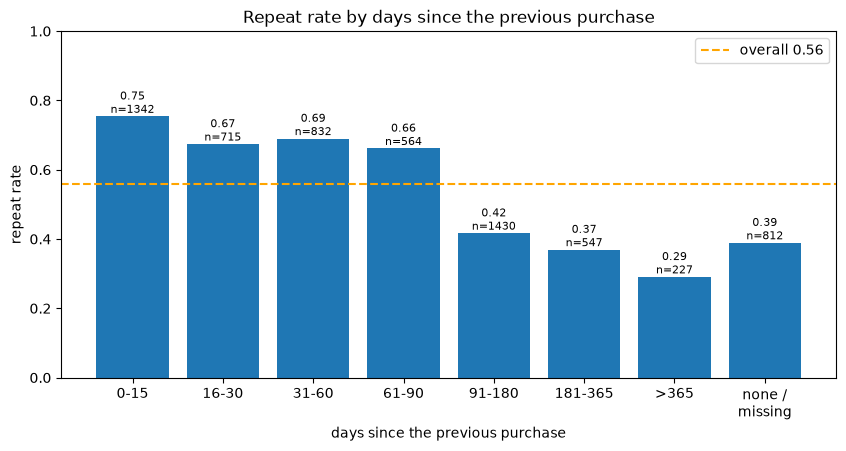

In [41]:
bins = [0, 15, 30, 60, 90, 180, 365, np.inf]
labels = ["0-15", "16-30", "31-60", "61-90", "91-180", "181-365", ">365"]
recency = pd.cut(df_eda["days_since_previous_purchase"], bins=bins, labels=labels, include_lowest=True)
recency = recency.cat.add_categories("none /\nmissing").fillna("none /\nmissing")
by_recency = df_eda.groupby(recency, observed=True)[target_col].agg(["mean", "size"])

plt.figure(figsize=(10, 4.5))
plt.bar(by_recency.index.astype(str), by_recency["mean"])
plt.axhline(df_eda[target_col].mean(), color="orange", linestyle="--", label=f"overall {df_eda[target_col].mean():.2f}")
for i, (rate, n) in enumerate(zip(by_recency["mean"], by_recency["size"])):
    plt.text(i, rate + 0.01, f"{rate:.2f}\nn={n}", ha="center", fontsize=8)
plt.ylim(0, 1)
plt.xlabel("days since the previous purchase")
plt.ylabel("repeat rate")
plt.title("Repeat rate by days since the previous purchase")
plt.legend()
plt.show()

In [42]:
# first purchases (no previous purchase at all) vs the rest
first_purchase = df_eda["prior_purchase_count"] == 0
print(f"First purchases: {first_purchase.sum()} rows, repeat rate {df_eda.loc[first_purchase, target_col].mean():.3f}")
print(f"Other purchases: {(~first_purchase).sum()} rows, repeat rate {df_eda.loc[~first_purchase, target_col].mean():.3f}")

First purchases: 603 rows, repeat rate 0.333
Other purchases: 5866 rows, repeat rate 0.583


In [43]:
# frequency: repeat rate by number of purchases in the previous 90 days
freq = df_eda["purchase_count_90d"].clip(upper=6).astype("Int64").astype(str).replace({"6": "6+"})
df_eda.groupby(freq)[target_col].agg(["mean", "size"]).rename(columns={"mean": "repeat rate", "size": "rows"}).round(3)

,repeat rate,rows
purchase_count_90d,,
0,0.379,2889
1,0.568,1714
2,0.712,787
3,0.832,328
4,0.879,149
5,0.940,100
6+,0.986,502


* There is a **clear break at 90 days**: clients whose previous purchase was less than 90 days ago come back in 66% to 75% of the cases, after 90 days the rate falls to around 40%, and to 29% after one year. The relation is not linear, so `log1p` or bins can help a linear model.
* **First purchases** (no previous purchase at all) come back in only **33%** of the cases, close to the clients whose previous purchase was more than one year ago. The "none / missing" bar of the plot (39%) mixes these first purchases with rows where only `days_since_previous_purchase` is missing. This is why we want a flag `is_first_purchase` in Part 2 instead of just filling their missing values.
* **Frequency is even clearer**: with no purchase in the previous 90 days the repeat rate is 38%, with one purchase 57%, with three 83% and with six or more 99%.

#### **7.3. Rhythm of each Client**

The same number of days does not mean the same for every client: 30 days is a lot for a client who buys every week and very little for a client who buys once a year. So we test a ratio that compares the days since the previous purchase with the usual gap of the client: `days_since_previous_purchase / prior_mean_gap_days`. A value below 1 means this purchase came sooner than usual, and above 1 later than usual.

In [44]:
rhythm = df_eda["days_since_previous_purchase"] / df_eda["prior_mean_gap_days"].replace(0, np.nan)
pair = pd.DataFrame({"rhythm": rhythm, target_col: df_eda[target_col]}).dropna()

rho, _ = stats.spearmanr(pair["rhythm"], pair[target_col])
print(f"Spearman correlation with the target: {rho:.3f}")
pair.groupby(target_col)["rhythm"].describe()[["count", "25%", "50%", "75%"]].round(2)

Spearman correlation with the target: -0.056


,count,25%,50%,75%
repeat_purchase_90d,,,,
0,2018.0,0.34,0.93,1.61
1,3013.0,0.33,0.77,1.45


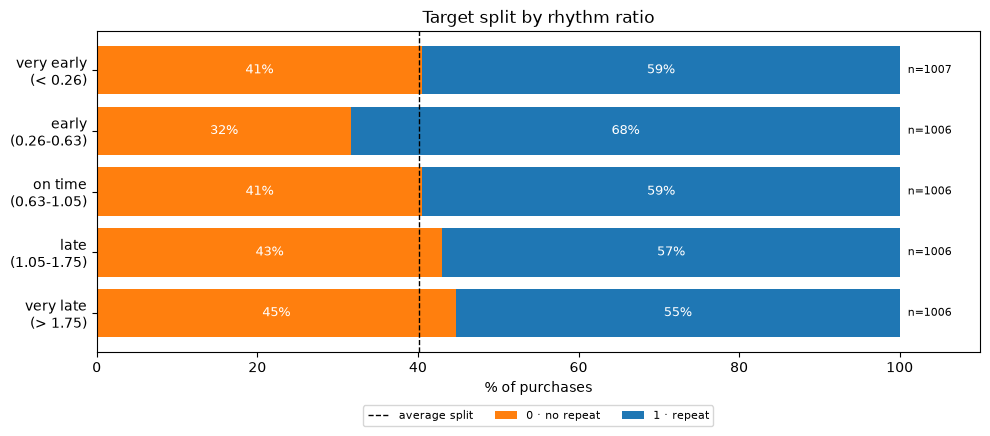

In [45]:
# share of 0 and 1 in each group of the ratio
pair["rhythm group"] = pd.qcut(pair["rhythm"], 5, labels=["very early\n(< 0.26)", "early\n(0.26-0.63)",
                                                           "on time\n(0.63-1.05)", "late\n(1.05-1.75)",
                                                           "very late\n(> 1.75)"])
shares = pd.crosstab(pair["rhythm group"], pair[target_col], normalize="index") * 100
rows = pair["rhythm group"].value_counts().reindex(shares.index)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(shares.index[::-1], shares[0][::-1], color="tab:orange", label="0 · no repeat")
ax.barh(shares.index[::-1], shares[1][::-1], left=shares[0][::-1], color="tab:blue", label="1 · repeat")
for i, (zero, one, n) in enumerate(zip(shares[0][::-1], shares[1][::-1], rows[::-1])):
    ax.text(zero / 2, i, f"{zero:.0f}%", va="center", ha="center", color="white", fontsize=9)
    ax.text(zero + one / 2, i, f"{one:.0f}%", va="center", ha="center", color="white", fontsize=9)
    ax.text(101, i, f"n={n}", va="center", fontsize=8)
ax.axvline(100 - 100 * pair[target_col].mean(), color="black", linestyle="--", linewidth=1, label="average split")
ax.set(xlim=(0, 110), xlabel="% of purchases", title="Target split by rhythm ratio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

The ratio is very similar in the two classes (median 0.93 for class 0 and 0.77 for class 1, Spearman −0.06). Only the "early" group (clients who came back at about half of their usual gap) stands out, with 68% of repeats against about 60% on average. The other groups are close to the average. So the idea makes sense, but alone the ratio has much less signal than the recency and the frequency. We keep it only as a candidate variable for Part 2, and the feature selection will decide.

#### **7.4. Categorical Variables**

For two categorical variables we use the **chi-square test** and the **Cramér's V** (from 0 = no association to 1 = perfect association). The chi-square is only reliable when the expected count of every cell is around 5 or more, so we also show the minimum expected count.

In [46]:
cat_rows = []
for col in cat_cols:
    x = df_eda[col].fillna("<missing>")
    table = pd.crosstab(x, df_eda[target_col])
    chi2, p_value, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    cat_rows.append({"feature": col, "levels": table.shape[0], "chi2": chi2, "p-value": p_value,
                     "Cramer's V": v, "min expected count": expected.min()})
pd.DataFrame(cat_rows).set_index("feature").sort_values("Cramer's V", ascending=False).round(4)

,levels,chi2,p-value,Cramer's V,min expected count
feature,,,,,
transport_method,81,527.2252,0.0000,0.2855,0.4403
payment_type,10,354.3527,0.0000,0.2340,1.7610
salesperson,10,260.7604,0.0000,0.2008,1.3208
commercial_zone,5,26.2955,0.0000,0.0638,0.4403
warehouse,3,10.1673,0.0062,0.0396,9.2453
document_series,3,0.0553,0.9727,0.0029,804.7834


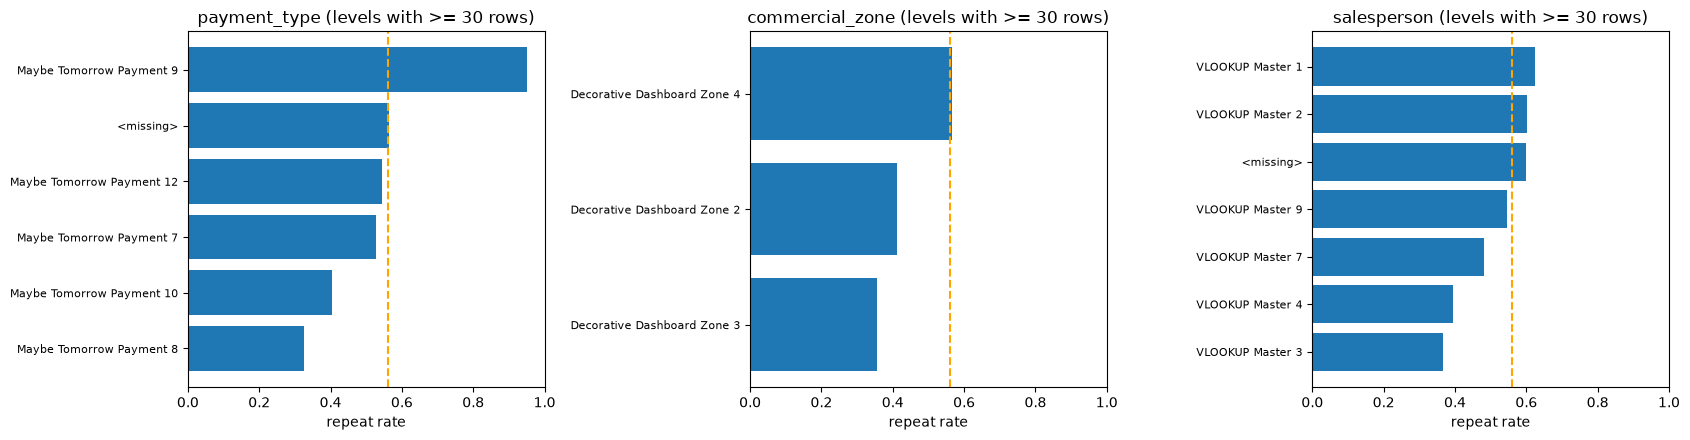

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["payment_type", "commercial_zone", "salesperson"]):
    by_level = df_eda.groupby(df_eda[col].fillna("<missing>"))[target_col].agg(["mean", "size"])
    by_level = by_level[by_level["size"] >= 30].sort_values("mean")
    ax.barh(by_level.index, by_level["mean"])
    ax.axvline(df_eda[target_col].mean(), color="orange", linestyle="--")
    ax.set(xlim=(0, 1), title=f"{col} (levels with >= 30 rows)", xlabel="repeat rate")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

* `transport_method`, `payment_type` and `salesperson` have a moderate association with the target (Cramér's V between 0.20 and 0.29). Some payment types have repeat rates far from the average, which makes sense: the payment terms can show the type of relationship with the client.
* The V of `transport_method` is partly high **because** it has 80 levels: many tiny levels with extreme rates push the V up (their expected counts are far below 5). Grouping the rare levels into "Other" in Part 2 is what makes this variable usable.
* `commercial_zone` and `warehouse` have a weak association, and `document_series` has none (V ≈ 0, p = 0.97).

### **8. Redundancy between Variables**

Two variables can both be related to the target and still say the same thing. To check this we use the Spearman correlation between all the numeric variables and list the pairs above 0.90.

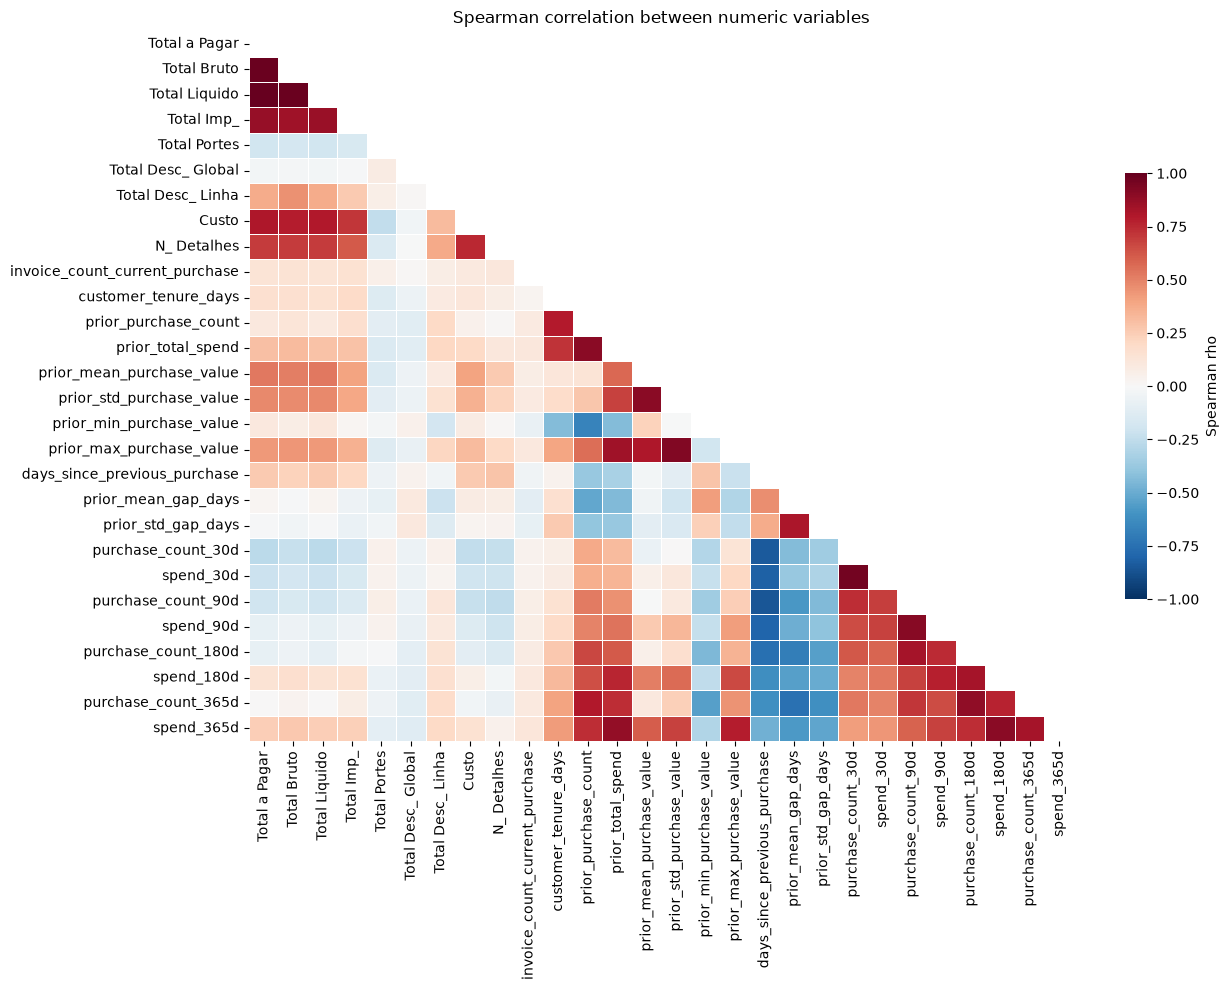

In [48]:
corr = df_eda[numeric_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=0.5,
            cbar_kws={"shrink": 0.6, "label": "Spearman rho"})
plt.title("Spearman correlation between numeric variables")
plt.tight_layout()
plt.show()

In [49]:
pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack().reset_index()
pairs.columns = ["variable A", "variable B", "Spearman rho"]
pairs = pairs.reindex(pairs["Spearman rho"].abs().sort_values(ascending=False).index)
pairs[pairs["Spearman rho"].abs() >= 0.90].round(3).reset_index(drop=True)

,variable A,variable B,Spearman rho
0,Total Liquido,Total a Pagar,1.000
1,Total Liquido,Total Bruto,0.991
2,Total Bruto,Total a Pagar,0.991
3,spend_30d,purchase_count_30d,0.965
4,prior_max_purchase_value,prior_std_purchase_value,0.923
5,spend_90d,purchase_count_90d,0.909
6,prior_total_spend,prior_purchase_count,0.903
7,spend_365d,spend_180d,0.901


In [50]:
# some links come from how the columns are built
no_recent = df_eda["purchase_count_90d"] == 0
print(f"Rows with no purchase in the last 90 days and days_since_previous_purchase > 90: "
      f"{(df_eda.loc[no_recent, 'days_since_previous_purchase'].dropna() > 90).mean():.1%}")

Rows with no purchase in the last 90 days and days_since_previous_purchase > 90: 100.0%


Eight pairs are above 0.90:
* `Total a Pagar`, `Total Bruto` and `Total Liquido` (0.99 to 1.00): they are linked by the accounting rules (net = gross − discounts), so one of them is enough.
* The count and the spend of the short windows: `purchase_count_30d` with `spend_30d` (0.97) and `purchase_count_90d` with `spend_90d` (0.91).
* `prior_purchase_count` with `prior_total_spend` (0.90), `prior_max_purchase_value` with `prior_std_purchase_value` (0.92) and `spend_365d` with `spend_180d` (0.90).

Some redundancy is not visible in the correlation matrix but comes from how the columns are built:
* `prior_mean_purchase_value` is exactly `prior_total_spend / prior_purchase_count` (3.6.1).
* When `purchase_count_90d` is 0, `days_since_previous_purchase` is always above 90 days (100% of the rows): no purchase in the last 90 days means the previous purchase is older than 90 days.

Redundancy is a problem mainly for the linear model (unstable coefficients), so in Part 3 we will use a redundancy filter and then the other feature selection methods.

### **9. The Clients Table (clientes.csv)**

The guidelines ask us to decide if and how to use `clientes.csv` through `customer_id`. First we check the quality of the table, then if it adds something new.

In [51]:
clientes_path=os.path.join("..","data","raw","clientes.csv")
df_clientes = pd.read_csv(clientes_path, sep=",")

print(f"Clients in clientes.csv: {len(df_clientes):,} | customer_id unique: {df_clientes['customer_id'].is_unique}")
print(f"Train clients found in clientes.csv: {df['customer_id'].isin(df_clientes['customer_id']).mean():.0%}")

# we only look at our clients, the other rows of the table never reach the model
clientes_train = df_clientes[df_clientes["customer_id"].isin(df["customer_id"])]
print(f"Train clients described: {len(clientes_train)}")

pd.DataFrame({
    "% missing": (100 * clientes_train.isna().mean()).round(1),
    "distinct values": clientes_train.nunique(),
    "distinct / clients": (clientes_train.nunique() / len(clientes_train)).round(3),
})

Clients in clientes.csv: 1,143 | customer_id unique: True
Train clients found in clientes.csv: 100%
Train clients described: 607


,% missing,distinct values,distinct / clients
customer_id,0.0,607,1.000
country_or_region,0.0,7,0.012
commercial_region,2.0,32,0.053
island,46.8,10,0.016
municipality,6.8,150,0.247
city,38.6,259,0.427
postal_area,6.6,188,0.310
postal_code,3.3,516,0.850
street,54.2,264,0.435
address,0.0,597,0.984


* `customer_id` is a good key: it is unique in the table and every client of the train is there. The table has 1,143 clients and the train only 607, but this is not a problem if we do a **left join** from the purchases (each purchase gets its client and the number of rows does not change) and we do not compute any statistic on the whole table.
* `customer_type` is **100% empty**.
* `company_name`, `address`, `street`, `postal_code` and `city` are almost unique for each client, so they identify the client instead of describing him (the same problem as using `customer_id`). Some of them are also half empty.
* The possible variables are the geography (`country_or_region` 7 levels, `commercial_region` 32, `island` 10, `municipality` 150) and `customer_since_year`.

In [52]:
# join the candidate columns to each purchase and measure the association with the target
candidates = ["country_or_region", "commercial_region", "island", "municipality", "customer_since_year"]
joined = df_eda.join(df_clientes.set_index("customer_id")[candidates], on="customer_id")

rows = []
for col in candidates:
    x = joined[col].astype("string").fillna("<missing>")
    table = pd.crosstab(x, joined[target_col])
    chi2, p_value, _, expected = chi2_contingency(table, correction=False)
    rows.append({"feature": col, "levels": table.shape[0],
                 "Cramer's V": np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))),
                 "min expected count": expected.min()})
pd.DataFrame(rows).set_index("feature").round(3)

,levels,Cramer's V,min expected count
feature,,,
country_or_region,7,0.066,0.440
commercial_region,33,0.264,0.440
island,11,0.148,4.403
municipality,151,0.365,0.440
customer_since_year,10,0.196,11.447


In [53]:
# is customer_since_year new information, or the same as customer_tenure_days?
purchase_year = pd.to_datetime(joined["purchase_date"]).dt.year
years_as_client = purchase_year - joined["customer_since_year"]
rho, _ = stats.spearmanr(years_as_client, joined["customer_tenure_days"], nan_policy="omit")
print(f"Spearman(purchase year - customer_since_year, customer_tenure_days) = {rho:.3f}")
print(f"Purchases made before the customer_since_year: {(years_as_client < 0).mean():.1%}")

Spearman(purchase year - customer_since_year, customer_tenure_days) = 0.917
Purchases made before the customer_since_year: 0.0%


**Decision on `clientes.csv` (to do in Part 2)**
* **We use only the geography that is not too detailed**: `country_or_region`, `commercial_region` and `island` (missing → "Missing", rare levels → "Other"). They describe where the client is, which can matter for logistics and sales. Their association with the target goes from weak (`country_or_region`, V = 0.07) to moderate (`commercial_region`, V = 0.26), but part of this last one comes from its 33 levels with few clients, like we saw with `transport_method`. The feature selection will decide if they stay.
* **We do not use** `customer_type` (empty), `company_name`, `address`, `street`, `postal_code` and `city` (they work like identifiers), and `municipality`: 150 levels for 607 clients is too detailed, and its high V (0.37) comes from the few clients in each municipality, not from a real pattern.
* **We do not use** `customer_since_year`: it has a correlation of 0.92 with `customer_tenure_days`, which is already in the train and is measured in days. The two tables are consistent (no purchase before the year the client joined), so the year does not add anything new.

A geography that is too detailed is almost an identifier: with only 607 clients, a municipality with two clients is almost the same as the client ID.

### **10. Identifiers and Random Noise**

The guidelines say that variables that look like identifiers should be treated critically. We check `ID`, `customer_id` and `random_noise` against the target and against the date.

In [54]:
id_frame = df.reset_index()
id_dates = pd.to_datetime(id_frame["purchase_date"]).astype("int64")

pd.DataFrame({
    "Spearman with target": [stats.spearmanr(id_frame[c], id_frame[target_col])[0] for c in ["ID", "customer_id", "random_noise"]],
    "Spearman with date": [stats.spearmanr(id_frame[c], id_dates)[0] for c in ["ID", "customer_id", "random_noise"]],
}, index=["ID", "customer_id", "random_noise"]).round(3)

,Spearman with target,Spearman with date
ID,0.012,0.011
customer_id,-0.116,-0.022
random_noise,-0.008,0.018


In [55]:
# why would customer_id be related to the target? Lets look at the clients with more purchases
top_clients = df["customer_id"].value_counts().head(5).index
(df[df["customer_id"].isin(top_clients)]
 .groupby("customer_id")[target_col].agg(["size", "mean"])
 .rename(columns={"size": "purchases", "mean": "repeat rate"})
 .sort_values("purchases", ascending=False).round(3))

,purchases,repeat rate
customer_id,,
103940,276,0.993
258332,200,1.000
755628,107,0.944
151492,88,0.852
519184,88,0.875


* **`ID`** is just the number of the row: it has no relation with the target or with the date. It stays as the index (we need it for the submission) and is never used as a variable.
* **`customer_id`** has a small correlation with the target (−0.12), but this is a **spurious relation**: the number is just a code, and the correlation only appears because a few very active clients (hundreds of purchases and repeat rates close to 1) have specific ID values. A model could learn these ID values and memorise these clients, which does not work for new purchases. So it is not used as a variable, only as the key to join `clientes.csv`.
* **`random_noise`** has no relation with anything (correlation ≈ 0 with the target and with the date). We do **not** delete it by hand: we keep it as a control in the feature selection (Part 3). A good feature selection method should remove it by itself.